# Simple OpenCV Road Following

**JetRacer laboratory guide**

**Goal:** Use the camera to find the orange road borders. Calculate a steering command. Drive the JetRacer at low speed.

At the end of this lab, you can:

- Capture an image from the CSI camera.
- Select orange pixels with HSV values.
- Remove noise from a mask.
- Find the road borders and estimate the road center.
- Calculate steering from the road-center position.
- Control the JetRacer with one dashboard.

**Before you start**

1. Put the JetRacer on a stable stand. Keep the wheels off the ground for the first motor test.
2. Make sure that you can stop the car at any time.
3. Run the code cells **from top to bottom**. Do not run two notebooks that use the same camera.
4. Use the calibration values from the previous JetRacer lab.

This lab uses **OpenCV**. It does not use a neural network.

## Step 1 — Capture an image

The CSI camera supplies an image with 640 × 360 pixels. The image contains three color channels.

The JetCam camera returns pixels in **BGR** order: blue, green, red. Keep this order for all steps in this lab.

**Procedure**

1. Run the cell.
2. Check the image.
3. Make sure that the orange track borders are visible.

This step captures **one image**. It then releases the camera. Step 6 starts the live camera again.

Image shape: (360, 640, 3)


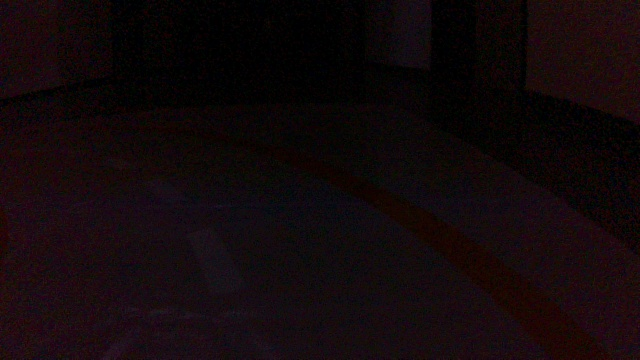

In [2]:
import cv2
import numpy as np
import ipywidgets as widgets

from jetcam.csi_camera import CSICamera
from IPython.display import display, Image

camera = CSICamera(
    width=640,
    height=360,
    capture_width=1280,
    capture_height=720,
    capture_fps=30
)

sample = camera.read().copy()
camera.cap.release()

print('Image shape:', sample.shape)
display(Image(data=cv2.imencode('.jpg', sample)[1].tobytes()))

## Step 2 — Select the orange track color

OpenCV uses **HSV** to describe a color:

- **H (hue):** The type of color.
- **S (saturation):** The strength of the color.
- **V (value):** The brightness.

**Procedure**

1. Move the sliders until the orange tape is **white** in the mask.
2. Keep the floor and other objects **black**.
3. Check the green pixels in the color image.
4. If most of the image becomes white, make the HSV range narrower.

**Important:** The camera uses BGR. Keep `cv2.COLOR_BGR2HSV` in every step. You must run Step 3 again after you change the sliders.


In [3]:
# HSV controls: adjust these values for your track
h_min = widgets.IntSlider(value=0, min=0, max=179, description='H min')
h_max = widgets.IntSlider(value=30, min=0, max=179, description='H max')
s_min = widgets.IntSlider(value=30, min=0, max=255, description='S min')
s_max = widgets.IntSlider(value=255, min=0, max=255, description='S max')
v_min = widgets.IntSlider(value=50, min=0, max=255, description='V min')
v_max = widgets.IntSlider(value=255, min=0, max=255, description='V max')

mask_view = widgets.Image(format='png', width=500)
result_view = widgets.Image(format='jpeg', width=500)
calibration_status = widgets.HTML()

def update_hsv(change=None):
    hsv = cv2.cvtColor(sample, cv2.COLOR_BGR2HSV)
    lower = np.array([h_min.value, s_min.value, v_min.value])
    upper = np.array([h_max.value, s_max.value, v_max.value])
    mask = cv2.inRange(hsv, lower, upper)

    result = sample.copy()
    result[mask > 0] = (0, 255, 0)  # Green = selected pixels
    mask_view.value = cv2.imencode('.png', mask)[1].tobytes()
    result_view.value = cv2.imencode('.jpg', result)[1].tobytes()

    fraction = np.count_nonzero(mask) / mask.size
    if fraction > 0.40:
        calibration_status.value = '<b>Too many pixels selected. Narrow the HSV range.</b>'
    else:
        calibration_status.value = 'Selected pixels: {:.1f}% of image'.format(fraction * 100)

for slider in [h_min, h_max, s_min, s_max, v_min, v_max]:
    slider.observe(update_hsv, names='value')

update_hsv()
display(widgets.VBox([
    widgets.VBox([h_min, h_max, s_min, s_max, v_min, v_max]),
    calibration_status,
    widgets.HTML('<b>HSV mask: white means selected</b>'), mask_view,
    widgets.HTML('<b>Selected pixels shown in green</b>'), result_view
]))


## Step 3 — Remove unwanted pixels

A good mask contains the orange borders but not the road surface.

We use three rules:

1. Ignore the top 100 image rows.
2. Close small gaps in the selected regions.
3. Remove very small regions and large background regions.

**Procedure**

1. Run this cell after you set the HSV sliders.
2. Compare the **raw mask** and the **clean mask**.
3. If the clean mask has no borders, return to Step 2 and adjust the sliders.
4. Run this cell again to save the new values.

The next steps use `HSV_LOWER`, `HSV_UPPER`, and `orange_mask()`.


HSV lower: [0, 30, 50]
HSV upper: [30, 255, 255]
Raw selected area: 0.0%
Clean selected area: 0.0%
Raw HSV mask:


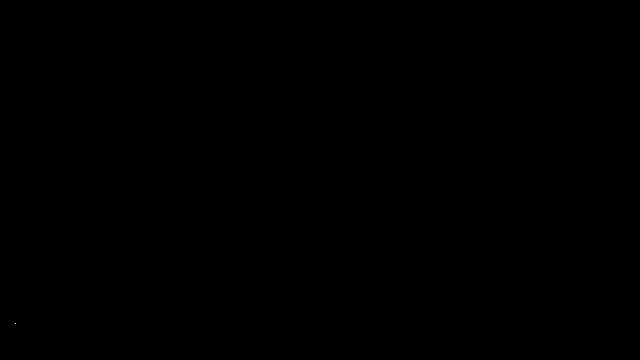

Clean mask:


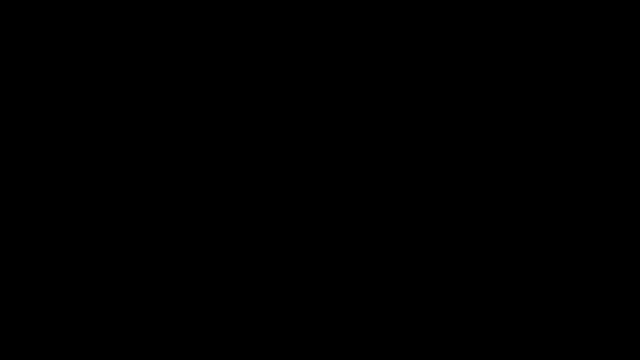

No usable orange region. Adjust Step 2 and run Step 3 again.


In [4]:
# Save HSV values from Step 2
HSV_LOWER = np.array([h_min.value, s_min.value, v_min.value])
HSV_UPPER = np.array([h_max.value, s_max.value, v_max.value])
ROI_Y = 100


def raw_orange_mask(frame):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, HSV_LOWER, HSV_UPPER)
    mask[:ROI_Y, :] = 0
    return mask


def orange_mask(frame):
    mask = raw_orange_mask(frame)

    # Close small gaps in the orange border
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    clean = np.zeros_like(mask)
    visible_area = frame.shape[1] * (frame.shape[0] - ROI_Y)

    for i in range(1, count):
        x, y, w, h, area = stats[i]
        # Reject small spots and very large background regions
        if area > 120 and h > 30 and area < 0.25 * visible_area:
            clean[labels == i] = 255

    return clean


raw = raw_orange_mask(sample)
clean = orange_mask(sample)
visible_pixels = sample.shape[1] * (sample.shape[0] - ROI_Y)
print('HSV lower:', HSV_LOWER.tolist())
print('HSV upper:', HSV_UPPER.tolist())
print('Raw selected area: {:.1f}%'.format(100 * np.count_nonzero(raw) / visible_pixels))
print('Clean selected area: {:.1f}%'.format(100 * np.count_nonzero(clean) / visible_pixels))
print('Raw HSV mask:')
display(Image(data=cv2.imencode('.png', raw)[1].tobytes()))
print('Clean mask:')
display(Image(data=cv2.imencode('.png', clean)[1].tobytes()))

if np.count_nonzero(clean) == 0:
    print('No usable orange region. Adjust Step 2 and run Step 3 again.')


## Step 4 — Fit curves to the road borders

The orange borders can be curved. We fit a quadratic curve through the detected points:

\[x(y) = ay^2 + by + c\]

- `y` is an image row.
- `x(y)` is the estimated horizontal position of the line at that row.
- `np.polyfit()` finds the curve coefficients.

**Important change:** We draw **all fitted candidates in yellow**. A candidate is used for steering only if it reaches the look-ahead row. A short line can therefore appear in yellow without moving the car.

**Procedure**

1. Run the next two cells.
2. Check the yellow curves.
3. Check the number of fitted lines and usable lines.
4. If there are no curves, return to Step 2 and Step 3.


In [5]:
def find_lines(frame, look_y):
    mask = orange_mask(frame)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    lines = []

    for i in range(1, count):
        x, y, w, h, area = stats[i]
        if area < 120 or h < 30:
            continue

        points = []
        for row in range(max(y, ROI_Y), min(y + h, frame.shape[0]), 5):
            xs = np.where(labels[row] == i)[0]
            if len(xs) >= 2:
                points.append([np.median(xs), row])

        if len(points) < 6:
            continue

        points = np.array(points)
        ys = points[:, 1]
        xs = points[:, 0]
        fit = np.polyfit(ys, xs, 2)
        line_x = float(np.polyval(fit, look_y))

        # Keep the fitted curve even when it cannot be used for steering
        usable = (ys.min() <= look_y <= ys.max()
                  and 0 <= line_x < frame.shape[1])

        lines.append({
            'x': line_x,
            'fit': fit,
            'y_min': int(ys.min()),
            'y_max': int(ys.max()),
            'usable': usable
        })

    return mask, lines


def draw_line(image, line, color):
    points = []
    for y in range(line['y_min'], line['y_max'] + 1):
        x = int(np.polyval(line['fit'], y))
        if 0 <= x < image.shape[1]:
            points.append([x, y])

    if len(points) > 1:
        cv2.polylines(image, [np.array(points, np.int32)], False, color, 3)


Fitted lines: 0
Usable at row 265: 0


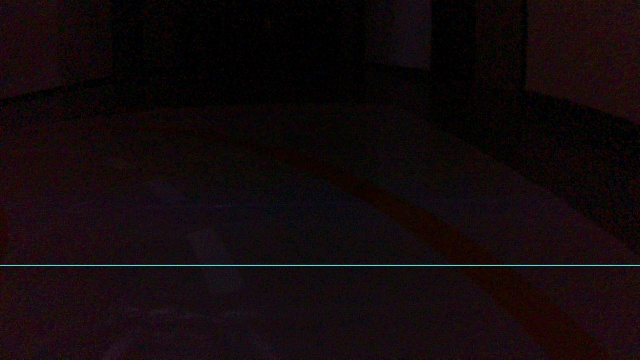

In [6]:
LOOK_Y = 265
mask, lines = find_lines(sample, LOOK_Y)
preview = sample.copy()
for line in lines:
    draw_line(preview, line, (0, 255, 255))  # All fitted lines: yellow

cv2.line(preview, (0, LOOK_Y), (639, LOOK_Y), (255, 255, 0), 1)
print('Fitted lines:', len(lines))
print('Usable at row {}: {}'.format(LOOK_Y, sum(line['usable'] for line in lines)))
display(Image(data=cv2.imencode('.jpg', preview)[1].tobytes()))


## Step 5 — Find the road center and calculate steering

The car follows the space **between** the orange borders.

- **Right outer border:** The rightmost usable border at the look-ahead row.
- **Left outer border:** The leftmost usable border at the look-ahead row.
- **Inner border:** Another usable border on the opposite side of the road.

When two borders are visible, the target is the midpoint:

\[x_{target} = (x_{left} + x_{right}) / 2\]

When only the outer border is usable, the program uses half the previous road width. If the width is unknown, it uses the **fallback half-width**.

**How to calculate steering**

1. For a 640-pixel image, the image center is at `x = 320`.
2. Calculate the road-center error: `(target_x - 320) / 320`.
3. Multiply the error by the **steering gain** and **steering sign**.
4. Limit the command to the tested range (here, `-0.25` to `+0.25`).

**Example:** If `target_x = 400`, the error is `+0.25`. With gain `0.75` and sign `+1`, the calculated command is `+0.1875`. The hardware steering calibration determines the physical direction of the wheels.

**Display colors:** Yellow = fitted line candidate, red = selected outer border, green = selected inner border, magenta = target, cyan = camera center. Yellow lines may be visible when no safe target is available.


In [7]:
MAX_STEER = 0.25  # Starting limit; change only after motor calibration
track = {'outer_x': None, 'width': None, 'target': None, 'misses': 0}

def reset_tracking():
    track['outer_x'] = None
    track['width'] = None
    track['target'] = None
    track['misses'] = 0


def follow_road(frame, side, look_y, fallback_half, gain, sign):
    mask, lines = find_lines(frame, look_y)
    image = frame.copy()
    height, width = frame.shape[:2]

    # Display all fitted lines, even if no steering target is available
    for line in lines:
        draw_line(image, line, (0, 255, 255))  # Yellow candidates

    valid = [line for line in lines if line['usable']]

    # Select the main (outer) border
    outer = None
    if valid:
        if track['outer_x'] is None:
            outer = max(valid, key=lambda p: p['x']) if side == 'Right' else min(valid, key=lambda p: p['x'])
        else:
            candidate = min(valid, key=lambda p: abs(p['x'] - track['outer_x']))
            if abs(candidate['x'] - track['outer_x']) < 100:
                outer = candidate

    # No valid border: stop steering and keep showing yellow candidates
    if outer is None:
        track['misses'] += 1
        track['target'] = None
        if track['misses'] >= 5:
            track['outer_x'] = None
        return image, mask, 0.0, 'NO USABLE BORDER | fitted={} | at row {}={}'.format(
            len(lines), look_y, len(valid))

    track['outer_x'] = outer['x']
    track['misses'] = 0
    draw_line(image, outer, (0, 0, 255))  # Red: selected outer border

    # Find the other (inner) border
    inner = None
    expected_width = track['width'] if track['width'] is not None else 2 * fallback_half
    for line in valid:
        if line is outer:
            continue
        distance = outer['x'] - line['x'] if side == 'Right' else line['x'] - outer['x']
        if 100 < distance < 550:
            if inner is None or abs(distance - expected_width) < abs(abs(inner['x'] - outer['x']) - expected_width):
                inner = line

    if inner is not None:
        draw_line(image, inner, (0, 255, 0))  # Green: inner border
        road_width = abs(outer['x'] - inner['x'])
        if track['width'] is None:
            track['width'] = road_width
        else:
            track['width'] = 0.8 * track['width'] + 0.2 * road_width
        target = (outer['x'] + inner['x']) / 2
        mode = 'BOTH BORDERS'
    else:
        half = track['width'] / 2 if track['width'] is not None else fallback_half
        target = outer['x'] - half if side == 'Right' else outer['x'] + half
        mode = 'OUTER ONLY - ESTIMATED CENTER'

    target = float(np.clip(target, 0, width - 1))
    if track['target'] is None:
        track['target'] = target
    else:
        track['target'] = 0.7 * track['target'] + 0.3 * target

    target_x = track['target']
    error = (target_x - width / 2.0) / (width / 2.0)
    steering = float(np.clip(sign * gain * error, -MAX_STEER, MAX_STEER))

    cv2.circle(image, (int(target_x), look_y), 8, (255, 0, 255), -1)
    cv2.line(image, (width // 2, 180), (width // 2, height - 1), (255, 255, 0), 1)

    message = '{} | target={:.0f} | error={:+.2f} | steering={:+.3f} | fitted={}'.format(
        mode, target_x, error, steering, len(lines))
    return image, mask, steering, message


### Test the steering calculation on the captured image

The preview **does not** move the wheels.

- **Yellow:** All fitted candidate lines.
- **Red:** Selected outer border, which must reach the look-ahead row.
- **Green:** Selected inner border.
- **Magenta:** Target point.
- **Cyan:** Camera center.

You can see yellow lines even if there is no valid steering target. Test both outer-border settings before live driving.


NO USABLE BORDER | fitted=0 | at row 265=0


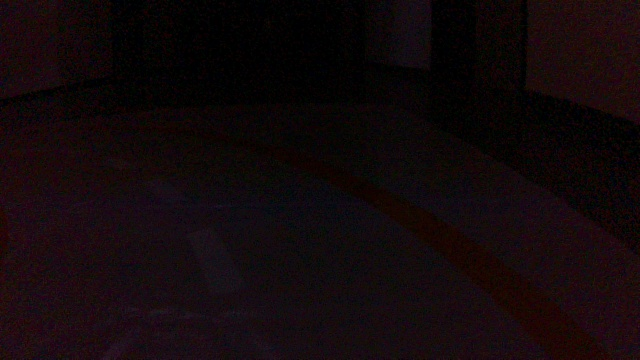

In [8]:
reset_tracking()
preview, mask, steering, message = follow_road(
    sample, side='Right', look_y=265,
    fallback_half=200, gain=0.75, sign=1
)
print(message)
display(Image(data=cv2.imencode('.jpg', preview)[1].tobytes()))

## Step 6 — Start live road tracking

**Procedure**

1. Keep the wheels off the ground.
2. Run Step 6A to Step 6D in order.
3. Check that the **raw mask** contains only the orange tape.
4. Check that the **clean mask** keeps the borders.
5. Check the yellow fitted lines in the camera image.
6. Check the red selected outer border and the green inner border.
7. Test steering with throttle disabled. Reverse **Steer sign** if the wheels turn away from the target.
8. Set a low throttle and enable the motor only after these checks.

**Important:** When tracking is lost, the code sends zero steering and zero throttle. A detected curve is not proof that the car is safe to drive. Stay close to the **STOP CAR** button.

**Important:** Calibrate HSV again in the live dashboard. Camera exposure and white balance can change after a restart. A saved-image mask may work while a live mask is empty.


### Step 6A — Prepare the camera and the car

This cell reopens the CSI camera. It also prints the HSV values selected in Step 3.

Use the calibration values from the previous JetRacer lab. They are examples for this car:

- `car.steering_gain` controls the hardware steering scale and direction.
- `car.steering_offset` corrects the mechanical center.
- `car.throttle_gain` scales the motor command.

These hardware settings are **different** from the OpenCV steering-gain slider. The OpenCV slider scales the road-center error.

**If the HSV values printed here are wrong:** Stop the live camera, go to Step 2, adjust the sliders, and run Step 3 again.


In [9]:
from jetracer.nvidia_racecar import NvidiaRacecar

# Stop any earlier camera session before opening a new one
try:
    camera.running = False
    camera.unobserve_all('value')
    camera.cap.release()
except (NameError, AttributeError):
    pass

car = NvidiaRacecar()
'''
initialise withe values that was calibrated in previus labs
'''

camera = CSICamera(
    width=640,
    height=360,
    capture_width=1280,
    capture_height=720,
    capture_fps=30
)
reset_tracking()
print('Camera ready. Motors stopped.')
print('Live HSV:', HSV_LOWER.tolist(), 'to', HSV_UPPER.tolist())


Camera ready. Motors stopped.
Live HSV: [0, 30, 50] to [30, 255, 255]


### Step 6B — Make one control dashboard

The dashboard contains the road settings, steering settings, and motor controls.

- **Outer border:** Select the left or right reference border. The red curve marks this border.
- **Look ahead:** Select the image row where steering is calculated. Smaller rows look farther ahead.
- **Fallback half:** Estimate half of the road width when only one border is usable.
- **Steering gain:** Set how strongly software responds to the road-center error.
- **Steer sign:** Reverse the software command direction if necessary.
- **Steering:** Read the calculated steering command. This is a read-only control.
- **Throttle:** Set a small forward command, not a speed in meters per second.

Throttle is applied only when automatic steering is enabled and a valid target is available. Steering is limited to **−0.25 to +0.25** in this lab.

The dashboard also shows the six HSV sliders from Step 2. Adjust them while you watch the **Raw HSV mask**. The orange lines must appear white before the algorithm can fit a curve.


In [10]:
# Camera views
live_image = widgets.Image(format='jpeg', width=640)
live_raw = widgets.Image(format='png', width=320)
live_clean = widgets.Image(format='png', width=320)
status = widgets.HTML(value='Live tracking is not started.')

# Road settings
outer_side = widgets.Dropdown(options=['Right', 'Left'], value='Right', description='Outer border')
look_ahead = widgets.IntSlider(value=265, min=180, max=320, step=5, description='Look ahead')
fallback_half = widgets.IntSlider(value=200, min=50, max=300, step=5, description='Fallback half')

# Steering settings
steering_gain = widgets.FloatSlider(value=0.75, min=0, max=1.5, step=0.05, description='Steering gain')
steer_sign = widgets.Dropdown(options=[('Positive', 1), ('Negative', -1)], value=1, description='Steer sign')
steering_command = widgets.FloatSlider(
    value=0.0, min=-MAX_STEER, max=MAX_STEER, step=0.005,
    description='Steering', disabled=True, readout_format='.3f'
)
enable_steering = widgets.Checkbox(value=False, description='Enable automatic steering')

# Motor settings
throttle = widgets.FloatSlider(
    value=0.0, min=0, max=0.20, step=0.005,
    description='Throttle', readout_format='.3f'
)
enable_throttle = widgets.Checkbox(value=False, description='Enable throttle')
stop_button = widgets.Button(description='STOP CAR', button_style='danger')


def apply_controls(change=None):
    road_ok = track['target'] is not None and track['misses'] == 0
    car.steering = float(steering_command.value) if road_ok and enable_steering.value else 0.0
    car.throttle = float(throttle.value) if road_ok and enable_steering.value and enable_throttle.value else 0.0


def stop_car(button=None):
    enable_throttle.value = False
    enable_steering.value = False
    car.throttle = 0.0
    car.steering = 0.0


def reset_controls(change=None):
    stop_car()
    reset_tracking()

for control in [enable_steering, enable_throttle, throttle]:
    control.observe(apply_controls, names='value')
for control in [outer_side, look_ahead, steer_sign]:
    control.observe(reset_controls, names='value')
stop_button.on_click(stop_car)


### Step 6C — Process live images

The camera is configured for 30 frames per second. We process every third frame.

For each processed frame, the code:

1. Finds the selected HSV pixels.
2. Removes noise and fits candidate lines.
3. Draws **all** fitted lines in yellow.
4. Selects valid borders and calculates the steering command.
5. Updates the camera image, raw mask, and clean mask.
6. Stops the car if the selected color is unreliable or no steering target is available.

**If the image has no red or green lines:** Look for yellow candidates, then inspect the raw and clean masks. The text shows the percentage of selected pixels.

The live processing reads the current HSV slider values for each processed frame. It does not rely on the fixed values saved in Step 3.


In [11]:
frame_count = 0

def process_frame(change):
    global frame_count
    frame_count += 1
    if frame_count % 3 != 0:
        return
    #frame = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)

    frame = change['new']  # BGR image from JetCam
    if frame is None:
        return
    frame = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)

    try:
        # Read HSV sliders on every processed frame.
        # The camera color may change after it restarts.
        HSV_LOWER[:] = [h_min.value, s_min.value, v_min.value]
        HSV_UPPER[:] = [h_max.value, s_max.value, v_max.value]

        raw = raw_orange_mask(frame)
        image, clean, command, message = follow_road(
            frame,
            side=outer_side.value,
            look_y=look_ahead.value,
            fallback_half=fallback_half.value,
            gain=steering_gain.value,
            sign=steer_sign.value
        )

        visible = frame.shape[1] * (frame.shape[0] - ROI_Y)
        selected_pct = 100 * np.count_nonzero(raw) / visible
        mask_too_broad = selected_pct > 40

        steering_command.value = 0.0 if mask_too_broad else command
        live_image.value = cv2.imencode('.jpg', image)[1].tobytes()
        live_raw.value = cv2.imencode('.png', raw)[1].tobytes()
        live_clean.value = cv2.imencode('.png', clean)[1].tobytes()

        if track['target'] is None or mask_too_broad:
            stop_car()
        apply_controls()

        warning = ' | HSV TOO BROAD: adjust Step 2' if mask_too_broad else ''
        status.value = (
            '<b>{}</b> | Raw selected: {:.1f}% | HSV {} to {}{}'
        ).format(message, selected_pct, HSV_LOWER.tolist(), HSV_UPPER.tolist(), warning)
    except Exception as error:
        stop_car()
        status.value = '<b>STOPPED: {}</b>'.format(error)


### Step 6D — Display the dashboard and start tracking

Run this cell. Keep the motor disabled while you check the result.

- **Camera:** Yellow curves are all fitted candidates. Red and green curves are usable road borders.
- **Raw HSV mask:** Shows all selected orange pixels below the ignored top area.
- **Clean mask:** Shows the regions that remain after noise filtering.
- **Status:** Shows the steering target and the percentage of selected pixels.

If the raw mask is mostly white, go back to Step 2. If the clean mask is black, the color range or region filters are too strict. If yellow curves appear but red/green do not, move **Look ahead** to a row covered by the detected lines.

The car stops when you change the outer border, look-ahead row, or steering sign.

If the raw HSV mask is black, adjust **H min/max**, **S min/max**, and **V min/max** in the live dashboard. Keep throttle and steering disabled. Make both orange borders white in the raw mask, then confirm they remain in the clean mask.


In [12]:
road_controls = widgets.VBox([
    widgets.HTML('<b>Road detection</b>'),
    outer_side, look_ahead, fallback_half
])

drive_controls = widgets.VBox([
    widgets.HTML('<b>Steering and throttle</b>'),
    steering_gain, steer_sign, steering_command,
    enable_steering, throttle, enable_throttle, stop_button
])

# Reuse the HSV sliders from Step 2. They now adjust live detection.
live_hsv_controls = widgets.VBox([
    widgets.HTML('<b>Live HSV calibration</b>'),
    widgets.HBox([
        widgets.VBox([h_min, h_max]),
        widgets.VBox([s_min, s_max]),
        widgets.VBox([v_min, v_max])
    ])
])

dashboard = widgets.VBox([
    widgets.HTML('<h3>Simple OpenCV Road Following</h3>'),
    widgets.HTML('<b>Camera and fitted lines</b>'),
    live_image,
    widgets.HBox([
        widgets.VBox([widgets.HTML('<b>Raw HSV mask</b>'), live_raw]),
        widgets.VBox([widgets.HTML('<b>Clean mask</b>'), live_clean])
    ]),
    status,
    live_hsv_controls,
    widgets.HBox([road_controls, drive_controls])
])

display(dashboard)
# Only one live callback should run
camera.running = False
camera.unobserve_all('value')
camera.observe(process_frame, names='value')
camera.running = True


In [15]:
car.throttle_gain = 0.8

## Step 7 — Stop the car and release the camera

Press **STOP CAR** when you want to stop driving. The live camera can stay on.

When the lab is complete, run the next cell. It stops the car, removes the live callback, and releases the camera.

**Do not run Step 1 or Step 6A while the live camera is running.** Stop and release the camera first.

In [13]:
# Stop motors before changing the detector
stop_car()

h_min.value = 8
h_max.value = 129

s_min.value = 36
s_max.value = 220

v_min.value = 128
v_max.value = 212

In [14]:
stop_car()
camera.running = False
camera.unobserve(process_frame, names='value')
camera.cap.release()
print('Car stopped. Camera released.')

Car stopped. Camera released.


In [47]:
# HSV settings for the reddish live-camera image
h_min.value = 155
h_max.value = 179

s_min.value = 40
s_max.value = 255

v_min.value = 70
v_max.value = 255

## Check your results

Complete these checks before you finish:

- [ ] The orange track lines are white in the raw mask. Most of the floor is black.
- [ ] The clean mask still contains the orange borders.
- [ ] Yellow fitted curves follow the detected borders in Step 4 and Step 6.
- [ ] Red and green curves appear when the borders reach the look-ahead row.
- [ ] The magenta target lies between two usable borders.
- [ ] The steering command changes when the road center moves left or right.
- [ ] The steering wheels turn towards the target with throttle disabled.
- [ ] **STOP CAR** sets steering and throttle to zero.
- [ ] If the mask is unreliable or tracking is lost, both commands are zero.

**Questions**

1. What changes when you move the look-ahead row down the image?
2. Why can a yellow curve appear without a red border?
3. What happens when only one border is usable?
4. What is the difference between the software steering gain and `car.steering_gain`?

**End of lab.**


In [48]:
print("Road valid:", track['target'] is not None)
print("Steering enabled:", enable_steering.value)
print("Throttle enabled:", enable_throttle.value)
print("Throttle slider:", throttle.value)
print("Throttle command:", car.throttle)
print("Throttle gain:", car.throttle_gain)

Road valid: False
Steering enabled: False
Throttle enabled: False
Throttle slider: 0.0
Throttle command: 0.0
Throttle gain: 0.3


In [49]:
car.throttle_gain = 0.8

Selected pixels: 19147


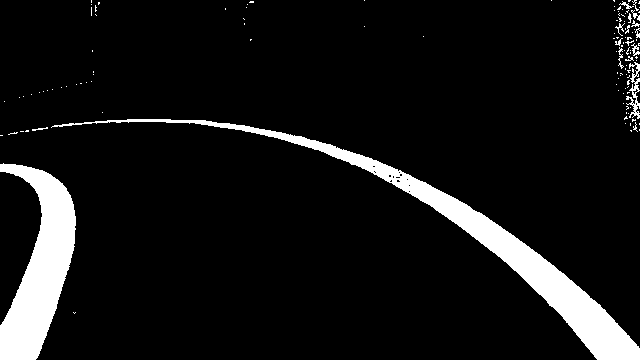

In [50]:
frame = camera.value.copy()

hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

lower = np.array([0, 131, 124])
upper = np.array([121, 220, 255])

mask = cv2.inRange(hsv, lower, upper)

print("Selected pixels:", np.count_nonzero(mask))
display(Image(data=cv2.imencode('.png', mask)[1].tobytes()))

In [13]:
frame = camera.value.copy()

lower = np.array([h_min.value, s_min.value, v_min.value])
upper = np.array([h_max.value, s_max.value, v_max.value])

mask_bgr = cv2.inRange(
    cv2.cvtColor(frame, cv2.COLOR_BGR2HSV), lower, upper
)

mask_rgb = cv2.inRange(
    cv2.cvtColor(frame, cv2.COLOR_RGB2HSV), lower, upper
)

print("BGR detected:", np.count_nonzero(mask_bgr))
print("RGB detected:", np.count_nonzero(mask_rgb))

BGR detected: 124
RGB detected: 291
